In [1]:
import pandas as pd
import numpy as np

In [2]:
print("смотрим статистику по зонам")
zone_stats = pd.read_csv("zone_stats.csv")
zone_stats

смотрим статистику по зонам


,zone,res_buildings,res_floor_m2,res_share,work_buildings,work_floor_m2,work_points,work_share,unclassified_buildings,res_levels_known_pct,work_levels_known_pct
0,Z01,19,87571,0.0177,13,44495,13,0.0097,14,100,85
1,Z02,115,2399483,0.4846,144,1740053,576,0.3791,67,97,69
2,Z04,2,33311,0.0067,32,329461,54,0.0718,258,100,78
3,Z05,68,765232,0.1545,54,252323,133,0.0550,59,100,76
4,Z06,98,780414,0.1576,47,348747,90,0.0760,134,46,79
5,Z07,149,784737,0.1585,118,691118,301,0.1506,37,99,87
6,Z08,47,101160,0.0204,24,1183948,8,0.2579,52,100,92


In [ ]:
calibration_df = pd.read_csv('calibration.csv')
points_df = pd.read_csv('points.csv')
area_df = pd.read_csv('area.csv')
flows_df = pd.read_csv('flows_template.csv')

area_df.head(10)

,номер,широта,долгота
0,1,55.917475,37.487362
1,2,55.922627,37.528873
2,3,55.924067,37.528150
3,4,55.924441,37.527962
4,5,55.925795,37.527279
5,6,55.927523,37.526408
6,7,55.929286,37.525424
7,8,55.930976,37.524659
8,9,55.931595,37.524344
9,10,55.932703,37.523782


In [5]:
points_df.head(10)

,id,место,широта,долгота,направление
0,P01A,Дирижабельная улица,55.94101,37.50945,на север
1,P01B,Дирижабельная улица,55.94101,37.50945,на юг
2,P02A,Лихачёвский проспект у Лихачёвского проезда,55.91884,37.49420,"на юг, в сторону Москвы"
3,P02B,Лихачёвский проспект у Лихачёвского проезда,55.91884,37.49420,"на север, из Москвы"
4,P03A,"Московская улица у станции «Водники», сразу за...",55.95392,37.51604,"на северо-восток, из города"
5,P03B,"Московская улица у станции «Водники», сразу за...",55.95392,37.51604,"на юго-запад, в город"
6,P04A,Новый бульвар между Спортивной улицей и улицей...,55.93824,37.50097,на восток
7,P04B,Новый бульвар между Спортивной улицей и улицей...,55.93824,37.50097,на запад
8,P05A,Институтский переулок,55.93083,37.51797,на восток
9,P05B,Институтский переулок,55.93083,37.51797,на запад


In [6]:
calibration_df.head(5)

,id,07:00-08:00,08:00-09:00
0,P02A,3188,3474
1,P02B,1334,1878
2,P08A,2221,2291
3,P14B,718,1100


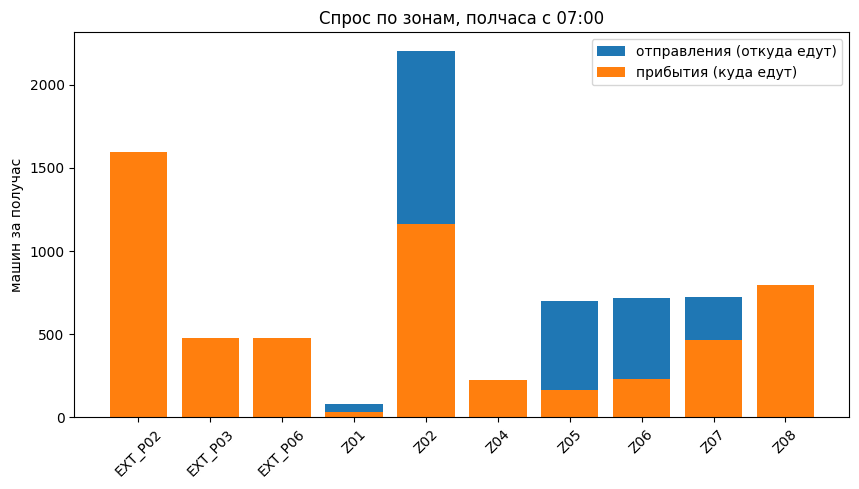

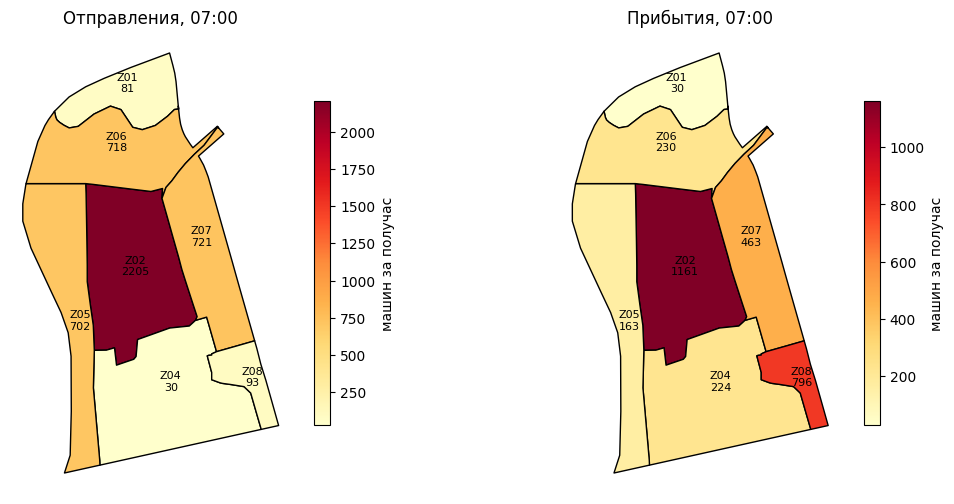

In [8]:
import json
import matplotlib.pyplot as plt
 
# ---------------- НАСТРОЙКИ ----------------
PERIOD = "07:00"            # какие полчаса показать: 07:00, 07:30, 08:00 или 08:30
ZONES_FILE = "zones_primary.geojson"
ZONE_COLUMN = "zone_id"
 

with open("periods.json", encoding="utf-8") as f:
    periods = json.load(f)
departures = periods[PERIOD]["departures"]
arrivals = periods[PERIOD]["arrivals"]
names = list(departures) 
 
# ---------------- 1. СТОЛБЦЫ ----------------
x = range(len(names))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i for i in x], [departures[n] for n in names],
       label="отправления (откуда едут)")
ax.bar([i for i in x], [arrivals[n] for n in names],
       label="прибытия (куда едут)")
ax.set_xticks(list(x))
ax.set_xticklabels(names, rotation=45)
ax.set_ylabel("машин за получас")
ax.set_title(f"Спрос по зонам, полчаса с {PERIOD}")
ax.legend()

# ---------------- 2. КАРТА ----------------
import geopandas as gpd
 
zones = gpd.read_file(ZONES_FILE)
column = ZONE_COLUMN
zones["zone"] = zones[column].astype(str)
zones["departures"] = zones["zone"].map(departures)
zones["arrivals"] = zones["zone"].map(arrivals)
 
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, col, title in [(axes[0], "departures", "Отправления"),
                           (axes[1], "arrivals", "Прибытия")]:
    zones.plot(column=col, cmap="YlOrRd", legend=True, edgecolor="black", ax=ax,
                   legend_kwds={"label": "машин за получас", "shrink": 0.7})
        
    for _, row in zones.iterrows():
        p = row.geometry.representative_point()
        ax.annotate(f"{row['zone']}\n{row[col]:.0f}", (p.x, p.y),
                    ha="center", fontsize=8)
    ax.set_title(f"{title}, {PERIOD}")
    ax.set_axis_off()
    
 
plt.show()